<a href="https://colab.research.google.com/github/unknxwNS/Ihopeitworks/blob/main/%D0%9C%D1%96%D1%85%D0%B0%D0%BB%D1%8C%D0%BE%D0%B2_%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

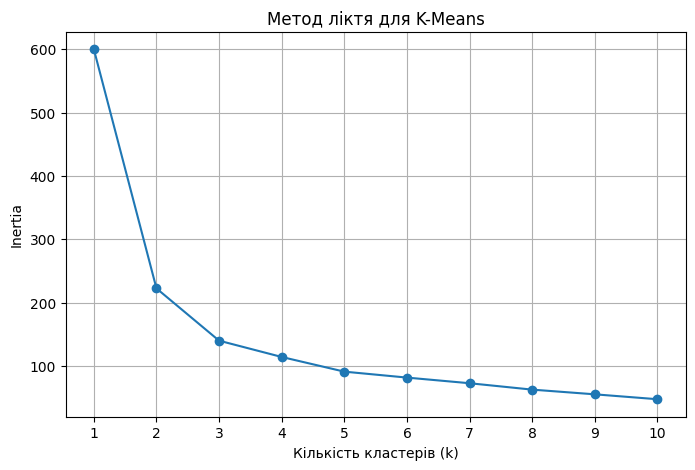

In [ ]:
# Стандартизація даних
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Метод ліктя
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Inertia")
plt.title("Метод ліктя для K-Means")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

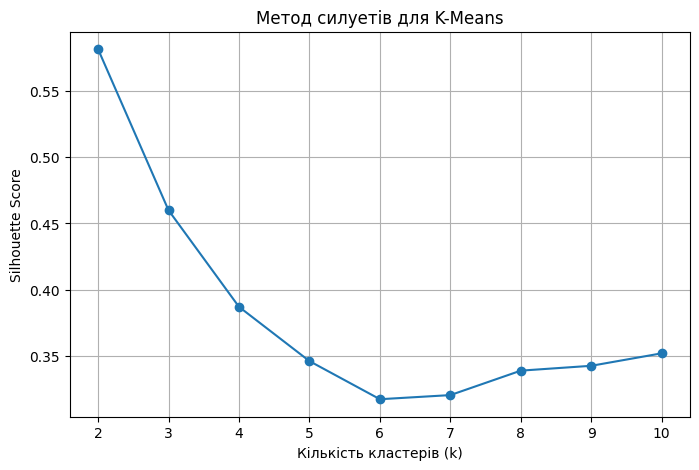

k = 2: Silhouette Score = 0.5818
k = 3: Silhouette Score = 0.4599
k = 4: Silhouette Score = 0.3869
k = 5: Silhouette Score = 0.3459
k = 6: Silhouette Score = 0.3171
k = 7: Silhouette Score = 0.3202
k = 8: Silhouette Score = 0.3387
k = 9: Silhouette Score = 0.3424
k = 10: Silhouette Score = 0.3518


In [ ]:
# Метод силуетів для k = 2–10
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker="o")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Silhouette Score")
plt.title("Метод силуетів для K-Means")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

# Виведення значень
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"k = {k}: Silhouette Score = {score:.4f}")

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

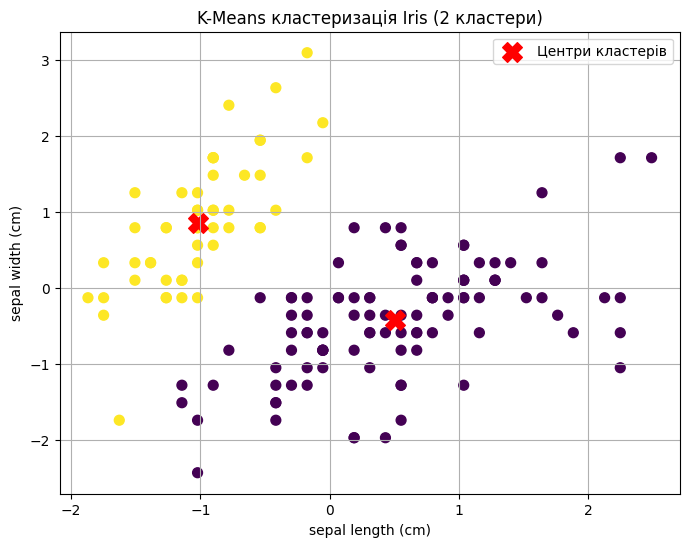

Координати центрів кластерів:
[[ 0.50728948 -0.42663134]
 [-1.01457897  0.85326268]]


In [ ]:
# Створення моделі K-Means для 2 кластерів
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

# Координати центрів кластерів
centers = kmeans.cluster_centers_

# Візуалізація перших двох ознак
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    s=50
)

# Відображення центрів кластерів
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Центри кластерів"
)

plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title("K-Means кластеризація Iris (2 кластери)")
plt.legend()
plt.grid(True)
plt.show()

# Виведення координат центрів
print("Координати центрів кластерів:")
print(centers[:, :2])

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
# Виведення назв усіх стовпців
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
# Перегляд структури таблиці
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
# Перевірка пропущених значень
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
# Підрахунок дублікатів
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
# Виведення описової статистики
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
# Формування ознак X та цільової змінної y
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

# Поділ даних на навчальну та тестову вибірки (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Стандартизація ознак
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

Розмір навчальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
# Створення моделі Random Forest
rf = RandomForestClassifier(random_state=42)

# Сітка параметрів для пошуку
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# GridSearchCV — пошук найкращих параметрів (5-fold CV)
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Навчання та пошук найкращих параметрів
grid_search.fit(X_train, y_train)

# Найкраща модель
best_rf = grid_search.best_estimator_

# Результати
y_pred = best_rf.predict(X_test)

print("Найкращі параметри:", grid_search.best_params_)
print("Середня CV accuracy:", grid_search.best_score_)
print("Тестова accuracy:", accuracy_score(y_test, y_pred))

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Найкращі параметри: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV accuracy: 0.9236736702527579
Тестова accuracy: 0.9144050104384134


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
# Створення моделі Logistic Regression
lr = LogisticRegression(random_state=42, solver='saga', max_iter=5000)

# Сітка параметрів для пошуку
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2']
}

# GridSearchCV для підбору параметрів (5-fold CV)
grid_search_lr = GridSearchCV(
    estimator=lr,
    param_grid=param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Навчання та пошук найкращих параметрів
grid_search_lr.fit(X_train, y_train)

# Найкраща модель
best_lr = grid_search_lr.best_estimator_

# Прогнозування на тестових даних
y_pred_lr = best_lr.predict(X_test)

# Виведення результатів
print("Найкращі параметри:", grid_search_lr.best_params_)
print("Середня CV accuracy:", grid_search_lr.best_score_)
print("Тестова accuracy:", accuracy_score(y_test, y_pred_lr))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Найкращі параметри: {'C': 0.1, 'penalty': 'l1'}
Середня CV accuracy: 0.7961286618457206
Тестова accuracy: 0.7661795407098121


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
# Створення моделі SVM
svm = SVC(random_state=42)

# Сітка параметрів для пошуку
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

# GridSearchCV для підбору параметрів (5-fold CV)
grid_search_svm = GridSearchCV(
    estimator=svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Навчання та підбір найкращих параметрів
grid_search_svm.fit(X_train, y_train)

# Найкраща модель
best_svm = grid_search_svm.best_estimator_

# Прогнозування на тестовій вибірці
y_pred_svm = best_svm.predict(X_test)

# Виведення результатів
print("Найкращі параметри:", grid_search_svm.best_params_)
print("Середня CV accuracy:", grid_search_svm.best_score_)
print("Тестова accuracy:", accuracy_score(y_test, y_pred_svm))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Найкращі параметри: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV accuracy: 0.8625182835973918
Тестова accuracy: 0.824634655532359


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [ ]:
# Порівняння тестової точності трьох моделей
results = {
    'Random Forest': accuracy_score(y_test, y_pred),
    'Logistic Regression': accuracy_score(y_test, y_pred_lr),
    'SVM': accuracy_score(y_test, y_pred_svm)
}

for name, accuracy in results.items():
    print(f"{name}: {accuracy:.4f}")

# Вибір моделі за найкращою CV-точністю
models = {
    'Random Forest': grid_search,
    'Logistic Regression': grid_search_lr,
    'SVM': grid_search_svm
}

best_model_name = max(models, key=lambda name: models[name].best_score_)
best_model = models[best_model_name].best_estimator_

print("\nНайкраща модель за CV-точністю:", best_model_name)
print("CV accuracy:", models[best_model_name].best_score_)

# Звіт classification_report для обраної моделі
y_pred_best = best_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Random Forest: 0.9144
Logistic Regression: 0.7662
SVM: 0.8246

Найкраща модель за CV-точністю: Random Forest
CV accuracy: 0.9236736702527579

Classification Report:
              precision    recall  f1-score   support

         0.0       0.83      0.45      0.59        22
         1.0       0.81      0.88      0.84        49
         2.0       0.94      0.87      0.90        85
         3.0       0.90      0.90      0.90        86
         4.0       0.94      0.99      0.96       237

    accuracy                           0.91       479
   macro avg       0.88      0.82      0.84       479
weighted avg       0.91      0.91      0.91       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

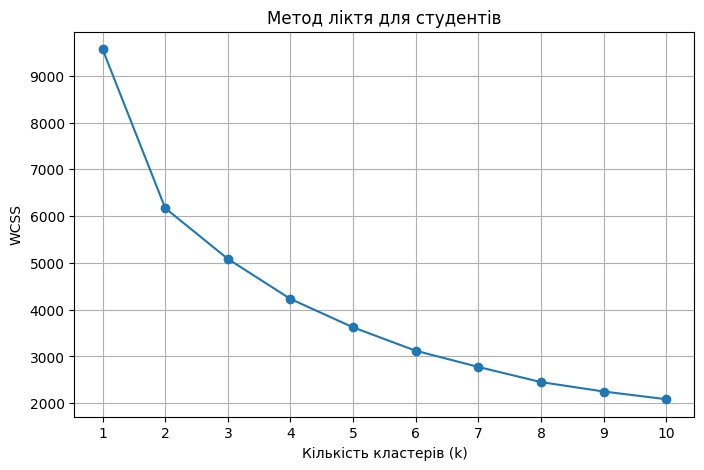

In [ ]:
# Вибираємо числові ознаки
features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_students = df[features]

# Стандартизація даних
scaler = StandardScaler()
X_students_scaled = scaler.fit_transform(X_students)

# Обчислення WCSS для 1–10 кластерів
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_students_scaled)
    wcss.append(kmeans.inertia_)

# Побудова графіка методу ліктя
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS')
plt.title('Метод ліктя для студентів')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

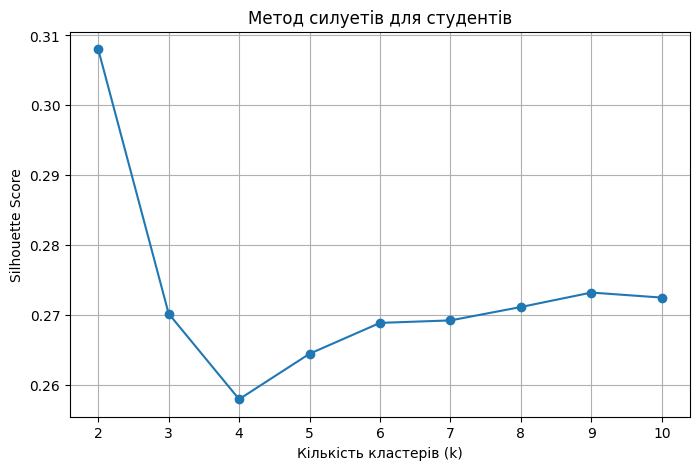

k = 2: Silhouette Score = 0.3080
k = 3: Silhouette Score = 0.2702
k = 4: Silhouette Score = 0.2580
k = 5: Silhouette Score = 0.2645
k = 6: Silhouette Score = 0.2689
k = 7: Silhouette Score = 0.2692
k = 8: Silhouette Score = 0.2712
k = 9: Silhouette Score = 0.2732
k = 10: Silhouette Score = 0.2725


In [ ]:
# Обчислення коефіцієнта силуета для 2–10 кластерів
silhouette_scores_students = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_students_scaled)

    score = silhouette_score(X_students_scaled, labels)
    silhouette_scores_students.append(score)

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores_students, marker='o')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Silhouette Score')
plt.title('Метод силуетів для студентів')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

# Виведення значень
for k, score in zip(range(2, 11), silhouette_scores_students):
    print(f'k = {k}: Silhouette Score = {score:.4f}')

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:
!pip install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [ ]:
# Видаляємо StudentID та GradeClass
X_pca = df.drop(columns=['StudentID', 'GradeClass'])

# Перевіряємо залишені ознаки
print("Кількість ознак:", X_pca.shape[1])
print("Назви ознак:")
print(X_pca.columns.tolist())

Кількість ознак: 13
Назви ознак:
['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [ ]:
# Стандартизація ознак
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca)

# Навчання PCA
pca = PCA()
X_pca_transformed = pca.fit_transform(X_pca_scaled)

# Частка поясненої дисперсії кожної компоненти
explained_variance = pca.explained_variance_ratio_

# Виведення результатів
for i, variance in enumerate(explained_variance, start=1):
    print(f"PC{i}: {variance:.4f} ({variance * 100:.2f}%)")

PC1: 0.1525 (15.25%)
PC2: 0.0861 (8.61%)
PC3: 0.0827 (8.27%)
PC4: 0.0807 (8.07%)
PC5: 0.0786 (7.86%)
PC6: 0.0779 (7.79%)
PC7: 0.0763 (7.63%)
PC8: 0.0760 (7.60%)
PC9: 0.0744 (7.44%)
PC10: 0.0738 (7.38%)
PC11: 0.0717 (7.17%)
PC12: 0.0675 (6.75%)
PC13: 0.0018 (0.18%)


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

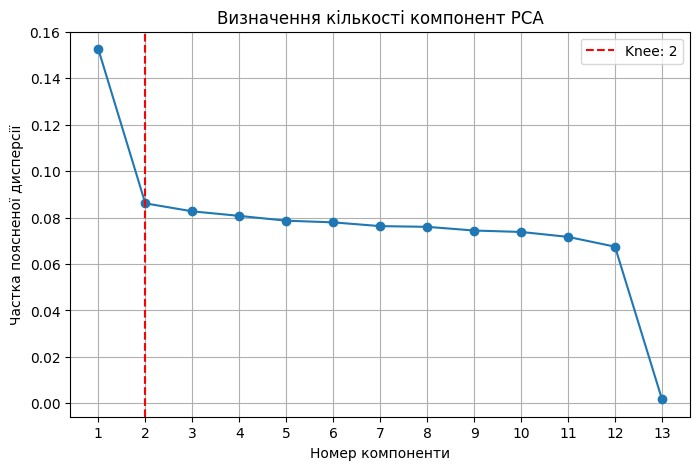

Оптимальна кількість компонент: 2


In [ ]:
# Визначення точки "ліктя"
components = range(1, len(explained_variance) + 1)

kneedle = KneeLocator(
    components,
    explained_variance,
    curve='convex',
    direction='decreasing'
)

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(components, explained_variance, marker='o')
plt.xlabel('Номер компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.title('Визначення кількості компонент PCA')

# Позначення точки "ліктя"
if kneedle.knee is not None:
    plt.axvline(kneedle.knee, color='red', linestyle='--',
                label=f'Knee: {kneedle.knee}')
    plt.legend()

plt.xticks(components)
plt.grid(True)
plt.show()

print("Оптимальна кількість компонент:", kneedle.knee)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Кількість компонент: 2
Збережена дисперсія: 0.2386 (23.86%)


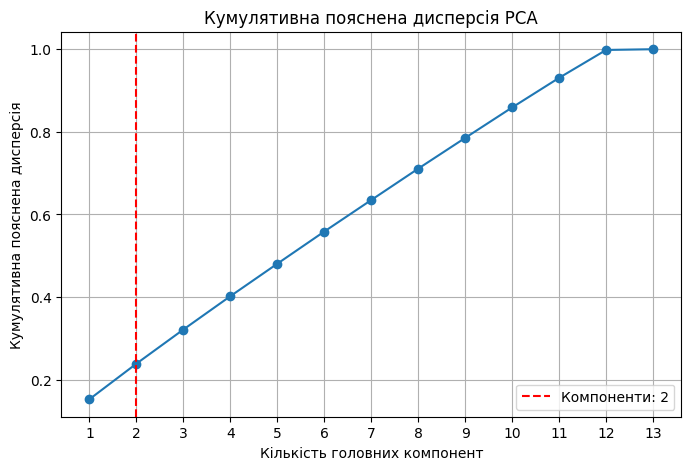

Розмір даних після PCA: (2392, 2)


In [ ]:
# Кумулятивна пояснена дисперсія
cumulative_variance = np.cumsum(explained_variance)

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1),
         cumulative_variance, marker='o')

plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна пояснена дисперсія')
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(True)

# Позначення знайденої кількості компонент
if kneedle.knee is not None:
    n_components = int(kneedle.knee)
    plt.axvline(n_components, color='red', linestyle='--',
                label=f'Компоненти: {n_components}')
    plt.legend()

    # Фактична частка дисперсії
    actual_variance = cumulative_variance[n_components - 1]
    print(f"Кількість компонент: {n_components}")
    print(f"Збережена дисперсія: {actual_variance:.4f} "
          f"({actual_variance * 100:.2f}%)")

plt.show()

# Перетворення даних через PCA
pca_final = PCA(n_components=n_components)
X_pca_final = pca_final.fit_transform(X_pca_scaled)

print("Розмір даних після PCA:", X_pca_final.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

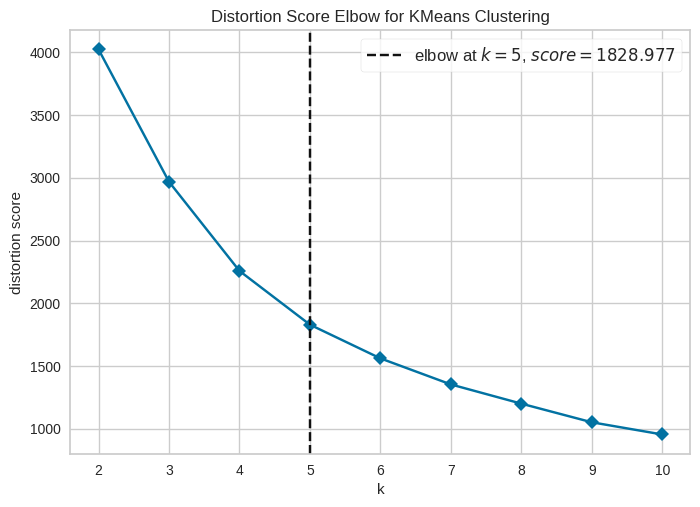

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
# Створення моделі K-Means
model = KMeans(random_state=42, n_init=10)

# Побудова методу ліктя на даних після PCA
visualizer = KElbowVisualizer(
    model,
    k=(2, 11),
    metric='distortion',
    timings=False
)

visualizer.fit(X_pca_final)

# Відображення графіка
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

У ході лабораторної роботи було досліджено K-Means, метод ліктя, коефіцієнт силуета та PCA. Для Iris оптимальна кількість кластерів за силуетом — 2, а для студентів метод ліктя після PCA визначив 5 кластерів. Класифікація за `GradeClass` прогнозує відомі категорії успішності, а кластеризація без неї самостійно групує студентів за схожими характеристиками. PCA зменшив кількість ознак із 13 до 2, але зберіг лише 23,86% дисперсії. Отже, кластеризація дозволяє знаходити групи даних без заздалегідь заданих категорій, хоча результати залежать від обраного методу та кількості кластерів.